# Job Matching AI Platform: algorithm walkthrough

This notebook drives the shared `matching` package (the same code the web app, the tests and the benchmarks use). It replaces the interactive menus of the original notebook, which is still in the git history (commit `7d4321b`).

1. Data loading and quality issues
2. The hierarchical cluster tree
3. A* search and why its heuristic is admissible
4. Greedy best-first, CSP and the exhaustive baseline compared
5. Employer → candidates, with constraint relaxation
6. Batch assignment: genetic algorithm vs the exact optimum

> The bundled datasets appear to be synthetic (see `docs/DATA.md`). The results show how the algorithms behave; they say nothing about real hiring quality.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "matching").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matching import Matcher, SEEKER_TO_JOB, JOB_TO_SEEKER
from matching.data import data_quality_report
from matching.csp import Constraints

m = Matcher(ROOT / "data")
m.stats()

{'total_jobs': 754,
 'total_seekers': 8124,
 'sectors': 20,
 'cities': 36,
 'jobs_without_skills': 435,
 'skill_vocabulary': 626,
 'tree_nodes': {'seeker_to_job': 1239, 'job_to_seeker': 6568}}

## 1. Data quality
Both datasets go through `matching.normalize`, which unifies sector, contract, education and city spellings. The report below lists what had to be fixed, and what can't be.

In [2]:
print(data_quality_report(ROOT / 'data'))

# Data quality report

- Jobs: 754 rows; seekers: 8124 rows; distance matrix: 48 cities.
- Jobs with no technical skills: 435 (58%). They cover whole sectors (Aerospace & Defense, Construction, E-Commerce, Healthcare, Mining, Pharmaceuticals, Public Sector, Renewable Energy, Telecommunications, Tourism & Hospitality, Transport & Logistics), so skills cannot be imputed from similar postings. The engine scores them as a weak skills match and the UI flags them.
- Distinct skill names: jobs 347, seekers 324, shared exactly: 45.
- Sector labels only in jobs: ['Finance']; only in seekers: ['Banking & Finance'].
- Contract labels jobs: ['Alternance', 'CDD', 'CDI', 'Freelance', 'Internship']; seekers: ['Alternance', 'CDD', 'CDI', 'Freelance', 'Stage'].
- Education labels jobs: ['Baccalaureate', 'Doctorat', "Ingénieur d'État", 'Licence', 'Master', 'No Formal Education']; seekers: ['Baccalaureate', 'Doctorat', "Ingénieur d'État", 'License', 'Master'].
- City spellings not literally in the distan

## 2. The cluster tree

Items are grouped by `sector → contract_type → edu_value → city`. Each node stores a summary of its items: the set of values present, and min/max education, experience and salary, plus the union of their skills. The search computes its bounds from these summaries.

In [3]:
tree = m.trees[SEEKER_TO_JOB]
leaves = list(tree.leaves())
print(f"job tree: {tree.n_nodes} nodes, {len(leaves)} leaves, "
      f"median {int(np.median([l.summary.n for l in leaves]))} job(s) per leaf")
leaf = max(leaves, key=lambda l: l.summary.n)
print("largest leaf path:", leaf.path())
print("summary:", {k: v for k, v in leaf.summary.__dict__.items() if k not in ('skill_union', 'city_idxs')})

job tree: 1239 nodes, 715 leaves, median 1 job(s) per leaf
largest leaf path: [('sector', 'Public Sector'), ('contract_type', 'Freelance'), ('edu_value', 12), ('city', 'Algiers')]
summary: {'n': 3, 'sectors': frozenset({'Public Sector'}), 'contracts': frozenset({'Freelance'}), 'edu_min': 12.0, 'edu_max': 12.0, 'lo_min': 0.0, 'hi_max': 1.0, 'salary_min': 43000.0, 'salary_max': 43000.0, 'skill_min_count': 0, 'any_listed': False, 'any_unlisted': True}


## 3. A* search

For a node *n*:
* **g(n)**: the exact cost of the criteria already fixed on the path. Every item below *n* shares those values.
* **h(n)**: for each remaining criterion, its cost at the most favourable value in the cluster (for example the highest salary offered, or the closest city).

Every per-criterion cost is monotone, so h never over-estimates, and it only tightens as clusters shrink. A* therefore pops items in true cost order, so its top-k is exactly the optimal top-k.

In [4]:
q = m.make_query(SEEKER_TO_JOB, sector="Retail", skills=["Inventory Management", "Retail Buying", "SQL"],
                 years=4, education="Master", city="Oran", salary=70000)
res = m.search(q, "astar", k=8)
print(res.stats.as_dict())
pd.DataFrame([{"id": h["id"], "title": h["title"], "sector": h["sector"], "city": h["city"],
               "salary": h["salary"], "score": h["match_score"],
               "skills": h["breakdown"]["skills"]["score"], "location": h["breakdown"]["location"]["score"]}
              for h in res.hits])

{'algorithm': 'astar', 'nodes_expanded': 58, 'nodes_generated': 224, 'items_scored': 9, 'max_frontier': 169, 'elapsed_ms': 10.416}


,id,title,sector,city,salary,score,skills,location
0,3,Store Manager,Retail,Oran,58000.0,73.34,40.0,100.0
1,706,Blasting Technician,Mining,Oran,128000.0,68.50,30.0,100.0
2,276,Blasting Technician,Mining,Oran,125000.0,68.50,30.0,100.0
3,643,RF Technician,Telecommunications,Oran,96000.0,68.50,30.0,100.0
4,613,Quantity Surveyor,Construction,Oran,71000.0,67.90,30.0,100.0
5,243,E-Commerce Manager,E-Commerce,Oran,78000.0,67.90,30.0,100.0
6,277,Registered Nurse,Healthcare,Oran,74000.0,67.30,30.0,100.0
7,175,Mine Engineer,Mining,Oran,115000.0,67.30,30.0,100.0


The Retail store-manager posting covers 2 of its 5 listed skills, so it wins. Jobs that list no skills at all (58% of postings) get a weak 30% skills score and fill the rest of the list. That is a limit of the data, not of the search.

Admissibility, checked empirically: the bound at every node is at most the exact cost of every item below it. The test suite (`tests/test_scoring.py`) checks this on many random queries.

In [5]:
scorer = m.scorers[SEEKER_TO_JOB]
pq = scorer.prepare(q)
exact = scorer.costs(pq) @ pq.weights
violations, checked = 0, 0
stack = [tree.root]
while stack:
    node = stack.pop()
    stack.extend(node.children.values())
    lb = scorer.lower_bounds(pq, node.summary) @ pq.weights
    violations += lb > exact[node.rows].min() + 1e-9
    checked += 1
print(f"checked {checked} nodes, violations: {violations}")
print(f"root bound {scorer.lower_bounds(pq, tree.root.summary) @ pq.weights:.4f} <= best exact cost {exact.min():.4f}")

checked 1239 nodes, violations: 0
root bound 0.0625 <= best exact cost 0.2666


## 4. Comparing the algorithms on the same query

In [6]:
rows = []
best = [h["match_score"] for h in m.search(q, "exhaustive", k=8).hits]
for alg in ["astar", "greedy", "csp", "exhaustive"]:
    r = m.search(q, alg, k=8)
    scores = [h["match_score"] for h in r.hits]
    rows.append({"algorithm": alg, "top score": scores[0], "mean top-8": np.mean(scores),
                 "same as optimal": np.allclose(scores, best), "items scored": r.stats.items_scored,
                 "nodes expanded": r.stats.nodes_expanded, "ms": round(r.stats.elapsed_ms, 2),
                 "relaxed": r.stats.extra.get("relaxed_constraints", "")})
pd.DataFrame(rows)

,algorithm,top score,mean top-8,same as optimal,items scored,nodes expanded,ms,relaxed
0,astar,73.34,68.65500,True,9,58,8.55,
1,greedy,68.50,57.15750,False,8,45,6.67,
2,csp,61.20,57.20625,False,18,37,3.81,"[max_distance_km, experience_slack, min_salary..."
3,exhaustive,73.34,68.65500,True,754,0,0.64,


Timing over 50 queries built from real seekers. The exhaustive baseline is a single vectorised NumPy pass, so on 754 jobs it beats the Python search loop in wall-clock time. A* scores far fewer items, which is the advantage that grows with catalogue size or with more expensive scoring.

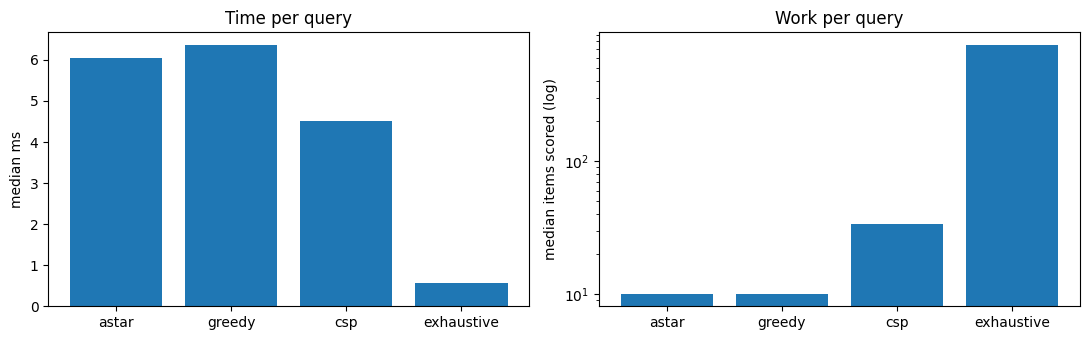

In [7]:
from matching.evaluation import dataset_queries
qs = dataset_queries(m, SEEKER_TO_JOB, 50, seed=0)
timing = {a: [] for a in ["astar", "greedy", "csp", "exhaustive"]}
scored = {a: [] for a in timing}
for qq in qs:
    for a in timing:
        r = m.search(qq, a, k=10)
        timing[a].append(r.stats.elapsed_ms)
        scored[a].append(r.stats.items_scored)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(timing.keys(), [np.median(v) for v in timing.values()])
ax[0].set_ylabel("median ms")
ax[0].set_title("Time per query")
ax[1].bar(scored.keys(), [np.median(v) for v in scored.values()])
ax[1].set_yscale("log")
ax[1].set_ylabel("median items scored (log)")
ax[1].set_title("Work per query")
plt.tight_layout()

## 5. Employer → candidates, and the CSP

The CSP turns sector, contract, education, distance, salary and experience into **hard** constraints. It prunes with node consistency and forward checking over the same tree. When fewer than *k* candidates survive, it relaxes constraints one at a time and reports which ones it dropped.

In [8]:
jq = m.make_query(JOB_TO_SEEKER, sector="Finance", education="Master", city="Algiers",
                  exp_lo=3, exp_hi=8, salary=90000, skills=["Risk Management", "Financial Modeling"])
for c in [Constraints(), Constraints(max_distance_km=50, min_salary_ratio=1.0, experience_slack=0)]:
    r = m.search(jq, "csp", k=8, constraints=c)
    print({k: r.stats.extra[k] for k in ("solutions", "pruned_by_node_consistency",
                                         "pruned_by_forward_checking", "relaxed_constraints")})
    print("  ", [(h["id"], h["city"], h["experience_years"], h["match_score"]) for h in r.hits])

{'solutions': 19, 'pruned_by_node_consistency': 96, 'pruned_by_forward_checking': 30, 'relaxed_constraints': []}
   [(745, 'Algiers', 6, 81.82), (3321, 'Algiers', 5, 81.82), (3543, 'Algiers', 7, 81.82), (6094, 'Algiers', 8, 81.82), (6528, 'Algiers', 4, 81.82), (3245, 'Algiers', 10, 79.85), (4165, "M'Sila", 7, 73.22), (4427, "M'Sila", 6, 73.22)]
{'solutions': 24, 'pruned_by_node_consistency': 29, 'pruned_by_forward_checking': 83, 'relaxed_constraints': ['max_distance_km']}
   [(745, 'Algiers', 6, 81.82), (3321, 'Algiers', 5, 81.82), (3543, 'Algiers', 7, 81.82), (6094, 'Algiers', 8, 81.82), (6528, 'Algiers', 4, 81.82), (4165, "M'Sila", 7, 73.22), (4427, "M'Sila", 6, 73.22), (2544, 'Mostaganem', 7, 70.6)]


## 6. Batch assignment: GA vs optimal

Assigning many seekers to job posts, where each posting has a number of `available posts`, is a weighted bipartite matching problem, and the Hungarian algorithm solves it exactly. That makes the genetic algorithm's quality measurable as a percentage of the true optimum.

,method,total_score,pct_of_optimal,assigned,elapsed_ms,generations_to_best
0,optimal (Hungarian),34.1697,100.00,60,0.34,NaN
1,greedy,33.9056,99.23,60,1.16,NaN
2,genetic algorithm,33.7292,98.71,60,2544.57,300.0


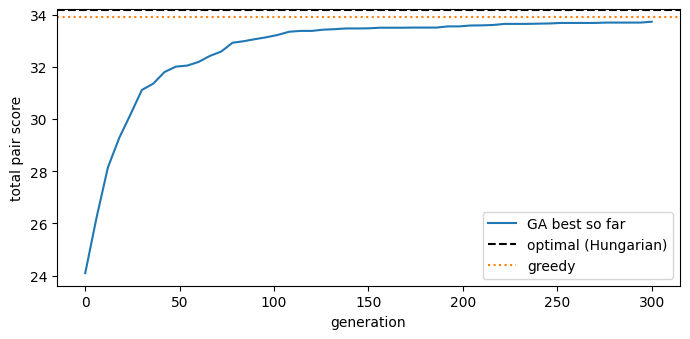

In [9]:
out = m.assign(n_seekers=60, n_jobs=20, seed=1, ga_params={"generations": 300})
display(pd.DataFrame(out["results"]))
opt_total = out["results"][0]["total_score"]
plt.figure(figsize=(7, 3.5))
plt.plot(np.linspace(0, 300, len(out["ga_history"])), out["ga_history"], label="GA best so far")
plt.axhline(opt_total, color="k", ls="--", label="optimal (Hungarian)")
plt.axhline(out["results"][1]["total_score"], color="tab:orange", ls=":", label="greedy")
plt.xlabel("generation"); plt.ylabel("total pair score"); plt.legend(); plt.tight_layout()

Full benchmarks (planted-match recovery, agreement with the optimum, timing, GA vs optimal) are in [`docs/BENCHMARKS.md`](../docs/BENCHMARKS.md). Regenerate them with `python -m matching evaluate`.